# 01 番茄叶片八分类：数据准备

本研究统一使用七种番茄病害与健康叶片八个类别。PlantVillage `color` 是模型训练数据来源，PlantDoc 是独立外部评价来源。**PlantDoc 原目录 `train` 与 `test` 只表示来源，不参与本研究训练、验证、模型选择或超参数调整。**

从第一格依次运行。数据准备会打开图片检查有效性、计算完全重复哈希，并按种子 42 生成约 70% / 15% / 15% 的 PlantVillage 分层划分；原图不会被修改。清单与质量报告写入 `data/splits/` 和 `data/metadata/`。本 Notebook 不训练模型。


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def find_project_root():
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        for root in (candidate, candidate / "plant-disease-project"):
            if (root / "configs" / "base.yaml").is_file():
                return root
    raise FileNotFoundError("请在项目根目录或 notebooks 目录打开本 Notebook。")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import load_config, load_labels

BASE = load_config(PROJECT_ROOT / "configs" / "base.yaml")
EXPERIMENTS = load_config(PROJECT_ROOT / "configs" / "experiments.yaml")
LABELS = load_config(PROJECT_ROOT / "configs" / "labels.yaml")
CLASS_NAMES = [item["label"] for item in load_labels(PROJECT_ROOT)]
assert len(CLASS_NAMES) == 8 and len(set(CLASS_NAMES)) == 8
assert [item["label_index"] for item in LABELS["classes"]] == list(range(8))
print("项目目录：", PROJECT_ROOT)
print("类别数量：", len(CLASS_NAMES), "；随机种子：", BASE["seed"])


项目目录： /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project
类别数量： 8 ；随机种子： 42


## 1. 核对固定标签与原始数量

类别编号 0—7 在训练、验证、推理和测试中保持相同。只使用指定八类；target spot、spider mites 等其他原始类别仍保留在磁盘，但不加入清单。

`tomato_leaf → 健康`、`tomato_leaf_yellow_virus → 黄化曲叶病毒病` 是本研究的**暂定映射**。现有源说明不足以证明它们逐图语义一致，原始文件名还有潜在错标提示；不得把相似名称或模型预测当作病理学确认。


In [2]:
from src.data import dataset_inventory

display(pd.DataFrame(LABELS["classes"]))
inventory = dataset_inventory(PROJECT_ROOT)
display(pd.DataFrame(inventory))


,label,label_index,plantvillage_class,plantdoc_classes,display_name,mapping_status
0,tomato_bacterial_spot,0,tomato_bacterial_spot,[tomato_leaf_bacterial_spot],番茄细菌斑病,source_label_correspondence
1,tomato_early_blight,1,tomato_early_blight,[tomato_early_blight_leaf],番茄早疫病,source_label_correspondence
2,tomato_late_blight,2,tomato_late_blight,[tomato_leaf_late_blight],番茄晚疫病,source_label_correspondence
3,tomato_leaf_mold,3,tomato_leaf_mold,[tomato_mold_leaf],番茄叶霉病,source_label_correspondence
4,tomato_septoria_leaf_spot,4,tomato_septoria_leaf_spot,[tomato_septoria_leaf_spot],番茄斑枯病,source_label_correspondence
5,tomato_tomato_mosaic_virus,5,tomato_tomato_mosaic_virus,[tomato_leaf_mosaic_virus],番茄花叶病毒病,source_label_correspondence
6,tomato_tomato_yellow_leaf_curl_virus,6,tomato_tomato_yellow_leaf_curl_virus,[tomato_leaf_yellow_virus],番茄黄化曲叶病毒病,provisional
7,tomato_healthy,7,tomato_healthy,[tomato_leaf],健康番茄叶片,provisional


,dataset,original_split,class_name,label,label_index,image_count
0,plantvillage,color,tomato_bacterial_spot,tomato_bacterial_spot,0,2127
1,plantdoc,train,tomato_leaf_bacterial_spot,tomato_bacterial_spot,0,101
2,plantdoc,test,tomato_leaf_bacterial_spot,tomato_bacterial_spot,0,9
3,plantvillage,color,tomato_early_blight,tomato_early_blight,1,1000
4,plantdoc,train,tomato_early_blight_leaf,tomato_early_blight,1,79
5,plantdoc,test,tomato_early_blight_leaf,tomato_early_blight,1,9
6,plantvillage,color,tomato_late_blight,tomato_late_blight,2,1909
7,plantdoc,train,tomato_leaf_late_blight,tomato_late_blight,2,101
8,plantdoc,test,tomato_leaf_late_blight,tomato_late_blight,2,10
9,plantvillage,color,tomato_leaf_mold,tomato_leaf_mold,3,952


## 2. 扫描质量并生成可复现划分

以下单元实际执行扫描。明确损坏图片和完全重复文件从研究清单中排除，原始图像、原始标注和来源元数据保留。存在跨类别完全重复时，按质量报告记录的规则处置，不猜测真实类别。

可可靠恢复的官方来源组优先用于分组划分。官方分组覆盖有限，花叶病毒类缺少官方分组匹配；无法恢复的样本使用保守的独立标识。**哈希无重复、来源组无交叉仍不能证明所有生物叶片或近重复照片均已隔离。** 不要求对数万张图逐张人工审核。

首次扫描需要几分钟。准备完成后保持清单固定，再进行 02—05；研究过程中修改数据或配置后，应重新准备并重新训练。


In [3]:
from src.data import prepare_manifests

summary = prepare_manifests(
    PROJECT_ROOT,
    load_config(PROJECT_ROOT / "configs" / "labels.yaml"),
    seed=42,
)
print("当前数据指纹：", summary["fingerprint"])
print("各清单样本数：")
display(pd.DataFrame([{"manifest": name, "samples": count}
                      for name, count in summary["counts"].items()]))
print("各类样本数与划分：")
display(pd.DataFrame(summary["per_class"]))
print("质量与来源分组报告：")
display(summary["quality"])


当前数据指纹： 65e16a548fb193b9d39fdb5114591eeb9fd90d17afbfa6a28865d9b59300a815
各清单样本数：


,manifest,samples
0,pv_train,10543
1,pv_val,2264
2,pv_test,2259
3,plantdoc_external_train,569
4,plantdoc_external_test,60
5,plantdoc_external_all,629


各类样本数与划分：


,label_index,label,pv_train,pv_val,pv_test,plantdoc_external_train,plantdoc_external_test,plantdoc_external_all
0,0,tomato_bacterial_spot,1488,320,319,68,5,73
1,1,tomato_early_blight,700,151,149,68,8,76
2,2,tomato_late_blight,1331,285,285,92,10,102
3,3,tomato_leaf_mold,664,144,144,69,4,73
4,4,tomato_septoria_leaf_spot,1240,266,265,108,9,117
5,5,tomato_tomato_mosaic_virus,261,56,56,43,10,53
6,6,tomato_tomato_yellow_leaf_curl_virus,3750,804,803,66,6,72
7,7,tomato_healthy,1109,238,238,55,8,63


质量与来源分组报告：


{'raw_target_images': 15824,
 'excluded': 129,
 'exclusion_reasons': {'source_annotation': 72,
  'duplicate_content_or_confirmed_photo': 40,
  'duplicate_label_conflict': 17},
 'pv_known_leaf_group_images': 9735,
 'pv_source_unknown_images': 5331,
 'plantdoc_raw_by_source': {'train': 675, 'test': 69},
 'source_annotation_scope': '复用旧人工初筛中有具体内容/标注依据的排除；不沿用缺少分组即排除的旧政策，也不代表八类均已人工审核。',
 'leaf_map_sha256': '3b4b253683c6911744959a3870a92509b1faa1ee34e9f8585e21d0fe6337a25b',
 'limitations': ['未匹配官方来源组的图像按单文件分组，不能据此宣称不存在同叶片泄漏。',
  '未重新执行全量近重复或专家病理审核，源标签错误和未识别同源图仍可能存在。',
  'PlantDoc 健康及黄化病毒映射为暂定语义对应；原始 train/test 均仅作最终外部评估。']}

## 3. 查看清洗后类别分布与样本

图中类别使用固定编号，中文名称见上方标签表。比较样本数和类别不平衡，后续重点报告 Macro-F1 与逐类 Recall。PlantDoc 来源数量应分别保留；合并外部集合经过整体去重，不把源目录文件数直接当作有效评价数。


,pv_train,pv_val,pv_test,plantdoc_external_train,plantdoc_external_test,plantdoc_external_all
label_index,,,,,,
0,1488,320,319,68,5,73
1,700,151,149,68,8,76
2,1331,285,285,92,10,102
3,664,144,144,69,4,73
4,1240,266,265,108,9,117
5,261,56,56,43,10,53
6,3750,804,803,66,6,72
7,1109,238,238,55,8,63


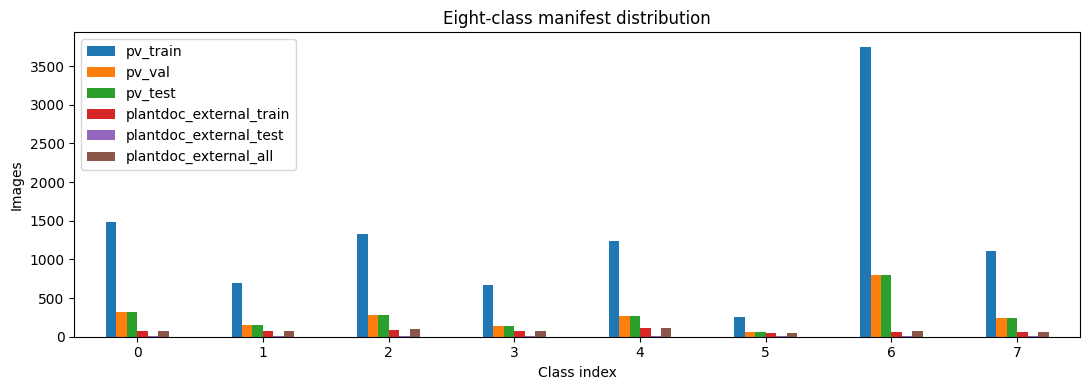

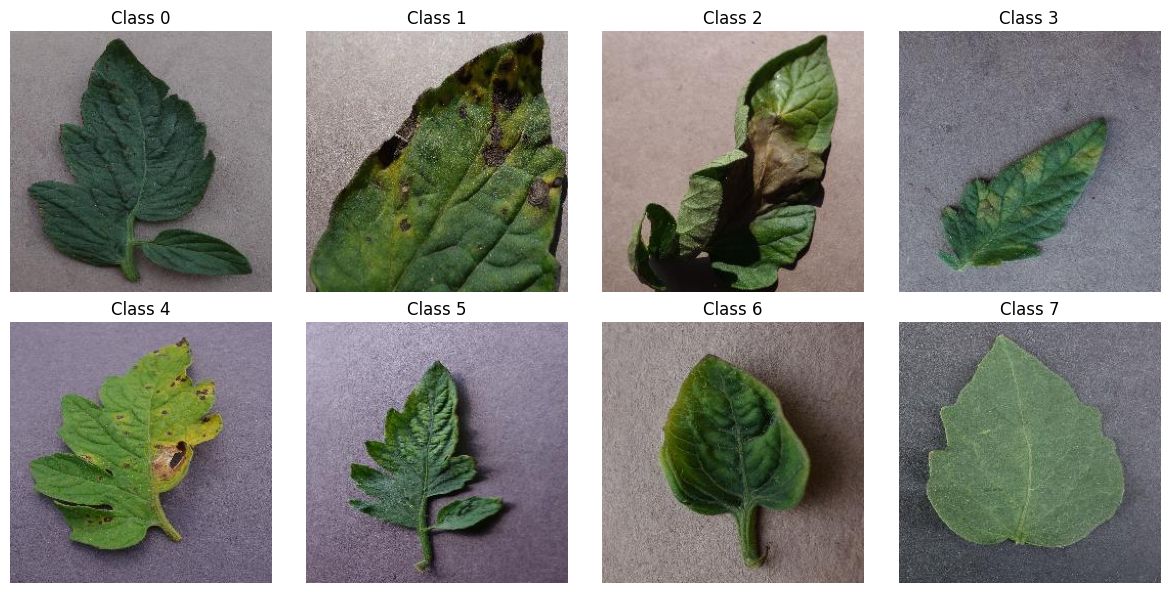

In [4]:
from src.data import read_manifest
from PIL import Image

manifest_names = ["pv_train", "pv_val", "pv_test", "plantdoc_external_train",
                  "plantdoc_external_test", "plantdoc_external_all"]
rows_by_split = {
    name: read_manifest(PROJECT_ROOT / "data" / "splits" / f"{name}.csv")
    for name in manifest_names
}
counts = pd.DataFrame({name: pd.Series([int(row["label_index"]) for row in rows]).value_counts()
                       for name, rows in rows_by_split.items()}).reindex(range(8), fill_value=0).fillna(0).astype(int)
counts.index.name = "label_index"
display(counts)
ax = counts.plot.bar(figsize=(11, 4), rot=0)
ax.set(xlabel="Class index", ylabel="Images", title="Eight-class manifest distribution")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for index, axis in enumerate(axes.flat):
    sample = next(row for row in rows_by_split["pv_train"] if int(row["label_index"]) == index)
    with Image.open(PROJECT_ROOT / sample["image_path"]) as image:
        axis.imshow(image.convert("RGB"))
    axis.set_title(f"Class {index}")
    axis.axis("off")
plt.tight_layout()
plt.show()


## 4. 检查数据加载

本单元只检查所有清单的首批图片能否读取，不开展模型训练，也不利用测试样本选择参数。数据质量扫描已经逐图验证文件可打开；完整验收记录由项目检查流程另行保存。


In [5]:
from src.data import build_transforms, make_loader

data_config = BASE["data"]
transform = build_transforms("none", **{key: data_config[key]
                            for key in ("image_size", "mean", "std") if key in data_config})
for name in manifest_names:
    loader = make_loader(PROJECT_ROOT / "data" / "splits" / f"{name}.csv", PROJECT_ROOT,
                         transform, batch_size=BASE["training"]["batch_size"],
                         shuffle=False, num_workers=0, seed=42)
    images, labels = next(iter(loader))
    assert images.shape[1:] == (3, data_config["image_size"], data_config["image_size"])
    assert labels.min().item() >= 0 and labels.max().item() < 8
    print(name, "：总数", len(loader.dataset), "首批图像", tuple(images.shape),
          "标签范围", (labels.min().item(), labels.max().item()))


pv_train ：总数 10543 首批图像 (16, 3, 224, 224) 标签范围 (0, 0)
pv_val ：总数 2264 首批图像 (16, 3, 224, 224) 标签范围 (0, 0)
pv_test ：总数 2259 首批图像 (16, 3, 224, 224) 标签范围 (0, 0)
plantdoc_external_train ：总数 569 首批图像 (16, 3, 224, 224) 标签范围 (0, 0)
plantdoc_external_test ：总数 60 首批图像 (16, 3, 224, 224) 标签范围 (0, 2)
plantdoc_external_all ：总数 629 首批图像 (16, 3, 224, 224) 标签范围 (0, 0)


## 结论记录

- **数据集构建与类别设置：** 本实验以 PlantVillage 和 PlantDoc 为数据来源，构建包含七种番茄叶片病害及一种健康状态的八分类任务。PlantVillage 用于模型训练、验证及同域测试，PlantDoc 仅用于跨场景外部评估。经过数据清洗，最终获得 PlantVillage 有效图像 15,066 张、PlantDoc 有效图像 629 张，共计 15,695 张。

- **数据清洗与质量检查：** 原始候选图像共 15,824 张，清洗过程中排除 129 张，其中因来源标注问题排除 72 张、重复内容或已确认的重复照片排除 40 张、重复图像标签冲突排除 17 张。数据处理过程中保留了必要的清洗记录与来源信息，以提高数据集的可追溯性。

- **数据划分与类别分布：** PlantVillage 数据集采用固定随机种子 42，按照约 70%/15%/15% 的比例划分为训练集、验证集和测试集，分别包含 10,543、2,264 和 2,259 张图像。经检查，三个数据集均包含完整的八个类别，各类别划分比例基本一致。但不同类别之间存在一定的不均衡，其中类别 6（番茄黄化曲叶病毒病）训练样本最多，为 3,750 张；类别 5（番茄花叶病毒病）最少，为 261 张。因此，后续模型评价除 Accuracy 外，还应重点关注 Macro-F1 及各类别识别表现。

- **数据加载验证：** 使用 PyTorch DataLoader 对各数据集进行加载测试，Batch Size 设置为 16，输入图像张量维度为 (16, 3, 224, 224)。训练集、验证集、测试集及 PlantDoc 外部评估集均能够正常加载，类别索引和数据格式符合后续模型训练要求。

- **数据局限性与后续安排：** PlantVillage 有 9,735 张图像具有已知来源叶片分组，另有 5,331 张图像缺少可靠的来源分组信息，因此尚不能完全排除同源相似图像跨数据集造成的数据泄漏。此外，本次未重新进行全量近重复检测及专家病理审核，PlantDoc 的健康叶片和黄化病毒类别映射仍存在一定语义不确定性。后续实验将固定当前数据划分，通过骨干网络对比、微调策略和数据增强实验进行模型优化，并使用独立测试数据评价模型的分类性能及跨场景泛化能力。
